# MATI 2026-27. Trabajo. Problema del Viajante (TSP) sobre la red de carreteras de España

*Datos © [OpenStreetMap contributors](https://www.openstreetmap.org/copyright), distribuidos con licencia [ODbL](https://opendatacommons.org/licenses/odbl/). Extracto de España publicado por [Geofabrik](https://download.geofabrik.de/europe/spain.html). Se mantiene la atribución, como es obligatorio.*

El objetivo del trabajo es **modelar la red de carreteras de la España peninsular como un grafo** y evaluar el rendimiento de varios algoritmos para resolver el **Problema del Viajante (TSP)** sobre distintas selecciones de ciudades (las capitales peninsulares, las ciudades de más de 100.000 habitantes...).

**Índice**

1. Construcción del grafo de la red vial peninsular
2. Filtrado del grafo: por tipo de carretera y selección de ciudades *(pendiente)*
3. Algoritmos para el Problema del Viajante: teoría y eficiencia *(pendiente)*
4. Estudio experimental de la eficiencia de los algoritmos *(pendiente)*
5. Conclusiones *(pendiente)*

> 📎 **Anexos.** El código que descarga los datos y construye el grafo **no está en este notebook**: se entrega aparte, como **Anexo A** (`anexos/descargar_red.py`) y **Anexo B** (`anexos/construir_grafo.py`), junto con el archivo del grafo `data/espana_red_maestra.graphml`.

> 🕸️ **Librería de grafos.** Se usa **NetworkX**, la misma que en las prácticas. El grafo se carga directamente con `nx.read_graphml`. [OSMnx](https://osmnx.readthedocs.io) solo interviene en el Anexo B para construirlo.

> ⚙️ **Entorno:** para ejecutar este notebook bastan `networkx` y `matplotlib` (ver `requirements.txt`). Si se usa el entorno `Python (MATI .venv)` de las prácticas, no hace falta instalar nada más.

In [1]:
# Librerías que se usan en todo el notebook
import networkx as nx            # crear y analizar grafos (la misma librería de las prácticas)

from tsp_utils import dibujar_red  # función de dibujo de la red de carreteras, comentada en tsp_utils.py

---

## Parte 1. Construcción del grafo de la red vial peninsular

<div style="border-left:5px solid #888;background:#F2F2F2;padding:10px 14px;margin:10px 0;border-radius:4px;">

**📋 ENUNCIADO**

Construir el **grafo de la red de carreteras de la España peninsular** que servirá de base al resto del trabajo: una única red "maestra", obtenida una sola vez, guardada en un archivo local y sobre la que se calcularán después las distancias y los tiempos entre ciudades.

Requisitos:

- **Ámbito:** España peninsular. Se excluyen las islas (Baleares y Canarias) y los enclaves que romperían la continuidad terrestre.
- **Carreteras:** hasta el nivel de la red primaria, para poder obtener subgrafos más pequeños filtrando aristas.
- **Atributos por tramo:** longitud en metros (`length`) y tiempo de viaje en segundos (`travel_time`).
- **Almacenamiento:** archivo local `data/espana_red_maestra.graphml`, comprobando que se puede volver a leer sin errores.

*[Pendiente: sustituir este resumen por el enunciado literal del trabajo.]*

</div>

<div style="border-left:5px solid #4C72B0;background:#EEF2FA;padding:10px 14px;margin:10px 0;border-radius:4px;">

**📚 TEORÍA**

**Grafo de carreteras.** Una red de carreteras se representa como un **grafo**: los **nodos** son las intersecciones (y los extremos de carretera) y las **aristas** son los tramos de carretera que las unen. Como hay vías de sentido único, el grafo es **dirigido**: una carretera de doble sentido se representa con *dos* aristas, una por cada dirección. Y es **ponderado**: cada arista lleva asociados una longitud y un tiempo.

Formalmente, $G=(V,E)$ con $V$ el conjunto de nodos y $E\subseteq V\times V$ el de aristas dirigidas, y dos funciones de peso $\ell, t : E \to \mathbb{R}_{>0}$:

$$\ell(e) = \text{longitud en metros},\qquad t(e)=\frac{\ell(e)}{v(e)}\quad\text{con } v(e)=\frac{v_{\text{km/h}}(e)}{3.6}\ \text{m/s}.$$

**Una arista es un tramo entero.** Los puntos intermedios de una carretera (sin cruces) no aportan información para calcular rutas, así que se **funden**: cada arista une dos intersecciones y su longitud es la de todo el tramo. El grafo es mucho más pequeño y las distancias no cambian.

**Multigrafo.** Puede haber varias carreteras distintas entre las mismas dos intersecciones, así que el grafo admite **aristas paralelas**: es un `nx.MultiDiGraph`. Cada arista se identifica con la terna $(u, v, \text{clave})$.

**Conectividad fuerte.** Un grafo dirigido es **fuertemente conexo** si para todo par de nodos $u, v$ existe un camino dirigido de $u$ a $v$. Es imprescindible para el TSP: garantiza que se puede llegar de cualquier ciudad a cualquier otra respetando los sentidos de circulación.

</div>

<div style="border-left:5px solid #8172B2;background:#F1EEF9;padding:10px 14px;margin:10px 0;border-radius:4px;">

**🔢 DATOS**

| Dato | Valor |
|---|---|
| Fuente | OpenStreetMap, extracto de España de Geofabrik (`spain-latest.osm.pbf`, ≈ 1,4 GB, del 19/10/2026) |
| Tipos de vía (`highway`) | `motorway`, `trunk`, `primary` y sus enlaces `_link` |
| Ámbito | España peninsular (sin Baleares, Canarias, Ceuta ni Melilla) |
| Peso en metros | `length` (a partir de la geometría de OpenStreetMap) |
| Peso en segundos | `travel_time` = `length` / velocidad |
| Velocidad | velocidad máxima de OpenStreetMap; si falta, la media de su tipo de vía |
| Archivo del grafo | `data/espana_red_maestra.graphml` (63 MB) |
| Código | Anexo A `anexos/descargar_red.py` y Anexo B `anexos/construir_grafo.py` |

</div>

<div style="border-left:5px solid #55A868;background:#EAF6ED;padding:10px 14px;margin:10px 0;border-radius:4px;">

**🧮 RESOLUCIÓN — Cómo se ha obtenido el grafo**

**Origen de los datos.** [OpenStreetMap](https://www.openstreetmap.org) (OSM) es un mapa colaborativo del mundo; **no es una fuente oficial**, aunque es una referencia habitual. [Geofabrik](https://download.geofabrik.de/europe/spain.html) publica cada día un **extracto** con todos los datos de España en un único archivo `spain-latest.osm.pbf` (formato binario comprimido de OSM, ≈ 1,4 GB). Se ha usado el del 19/10/2026.

**Descarga — Anexo A (`anexos/descargar_red.py`).** Descarga ese archivo a la carpeta `data/`. Si se corta la conexión, la descarga se reanuda donde se quedó (≈ 7 min en una conexión normal). Si el grafo ya existe, el script lo avisa y no descarga nada.

**Construcción — Anexo B (`anexos/construir_grafo.py`).** Convierte el extracto en el grafo en cinco pasos (≈ 6 min y ≈ 7 GB de memoria):

1. **Leer** del extracto solo las carreteras de tipo `motorway`, `trunk` y `primary` (y sus enlaces) y las coordenadas de sus nodos.
2. **Construir** el grafo dirigido: cada carretera de sentido único da una arista y cada una de doble sentido da dos.
3. **Quedarse con la península:** se conserva la mayor componente conexa, y las islas, Ceuta y Melilla desaparecen por ser pequeñas componentes desconectadas. Después se **simplifica** (se funden los tramos entre intersecciones) y se garantiza la **conectividad fuerte**.
4. **Calcular los pesos:** `length` en metros, `speed_kph` (la velocidad máxima etiquetada en OSM o, si falta, la media de su tipo de vía) y `travel_time` en segundos. Se descartan los atributos que no se van a usar.
5. **Guardar** en GraphML y **comprobar** que se puede volver a leer con tipos correctos.

**¿Por qué no se descargó directamente con la API Overpass?** Se probó primero: hacen falta 324 consultas encadenadas a un servidor público saturado y en unas 11 horas solo se completaron 19 (6 %). Con el extracto, todo el filtrado se hace en local en pocos minutos. El intento fallido se conserva en `docs/intento_overpass/` como justificación.

</div>

<div style="border-left:5px solid #55A868;background:#EAF6ED;padding:10px 14px;margin:10px 0;border-radius:4px;">

**🧮 RESOLUCIÓN — Cómo es el grafo**

**Tipo y tamaño.** Es un `nx.MultiDiGraph` (dirigido, con aristas paralelas) con **108.050 nodos** y **181.006 aristas** (≈ 110.000 km contando cada sentido de circulación). Es **fuertemente conexo**.

**Nodos (intersecciones y extremos).** El identificador de cada nodo es su número en OpenStreetMap (un entero). Atributos:

| Atributo | Significado |
|---|---|
| `x` | longitud, en grados |
| `y` | latitud, en grados |
| `street_count` | número de calles que confluyen en el nodo |

Según `street_count` hay varios tipos de nodo:

| `street_count` | Nodos | Qué es |
|---|---|---|
| 1 | 566 | extremo: fin de carretera o corte en la frontera |
| 2 | 2.571 | empalme entre dos vías distintas de OSM (por ejemplo, donde cambia el código de la carretera) |
| 3 | 97.630 | bifurcación o incorporación (por ejemplo, entradas y salidas de una autovía) |
| 4 | 6.127 | cruce de cuatro ramas |
| 5 o más | 1.156 | nudos complejos, como glorietas grandes |

Los nodos **no tienen nombre**: OpenStreetMap no nombra las intersecciones. Los nombres de las ciudades se asociarán a un nodo en la Parte 2.

**Aristas (tramos de carretera).** Cada arista va de un nodo origen a un nodo destino y se identifica con $(u, v, \text{clave})$. Atributos:

| Atributo | Tipo | Significado |
|---|---|---|
| `highway` | texto | tipo de vía (ver tabla siguiente) |
| `ref` | texto (opcional) | código de la carretera: `AP-7`, `A-4`, `N-340`... (en el 89,9 % de los km) |
| `name` | texto (opcional) | nombre de la vía, p. ej. «Autovía del Mediterráneo» (en el 73,8 % de los km) |
| `oneway` | booleano | `True` si es de sentido único; `False` si es de doble sentido (existe también la arista inversa) |
| `length` | número | longitud del tramo, **en metros** |
| `speed_kph` | número | velocidad usada, en km/h |
| `travel_time` | número | tiempo de recorrer el tramo, **en segundos** |

Hay 134.184 aristas de sentido único y 46.822 de doble sentido. Hay 2.746 pares de nodos unidos por más de una arista (aristas paralelas).

| `highway` | Qué es | Aristas | Km |
|---|---|---|---|
| `motorway` | autopista y autovía | 17.441 | 31.299 |
| `trunk` | vía rápida o carretera desdoblada | 48.996 | 31.251 |
| `primary` | carretera de la red principal | 69.200 | 39.313 |
| `motorway_link`, `trunk_link`, `primary_link` | enlaces, ramales y accesos de los anteriores | 18.615 + 14.104 + 12.650 | 5.852 + 1.600 + 814 |

**Ejemplo real de arista** (un tramo de la AP-8): `highway = motorway`, `ref = AP-8`, `oneway = True`, `length = 5895,6` m, `speed_kph = 100,0` y `travel_time = 212,2` s. Comprobación: $5895{,}6\ \text{m}\ /\ (100/3{,}6\ \text{m/s}) = 212{,}2\ \text{s}$. (En OSM este tramo tiene tres velocidades, 120, 80 y 100 km/h, y se usa su media.)

**Limitaciones.** `length` es la longitud del trazado en OSM, no el kilometraje oficial. `travel_time` es una estimación: no incluye tráfico, peajes ni semáforos y, cuando OSM no tiene velocidad máxima, usa la media de su tipo de vía. Como las aristas simplificadas no guardan su forma, al dibujarlas son líneas rectas entre intersecciones (las distancias no se ven afectadas).

</div>

**💻 CÓDIGO**

Se carga el grafo desde el archivo en la variable `G` (tarda unos 10 segundos) y se muestra su tamaño.

In [2]:
# Carga el grafo desde el archivo (NetworkX interpreta los números y booleanos del archivo)
G = nx.read_graphml("data/espana_red_maestra.graphml", node_type=int)
print(G)

MultiDiGraph with 108050 nodes and 181006 edges


Se dibuja el grafo completo.

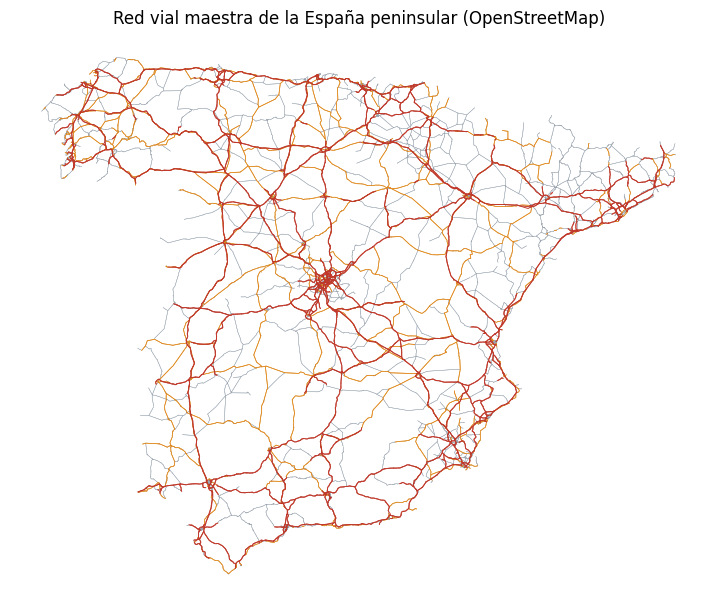

<Axes: title={'center': 'Red vial maestra de la España peninsular (OpenStreetMap)'}>

In [3]:
# Dibuja la red: rojo = autopista/autovía, naranja = vía rápida, gris = carretera principal
dibujar_red(G, titulo="Red vial maestra de la España peninsular (OpenStreetMap)")

**Fin de la Parte 1.** El grafo queda en la variable `G` (un `nx.MultiDiGraph` de NetworkX) para las siguientes partes del trabajo.

---